# Is Lalbagh's PM2.5 sensor trustworthy? A cross-check against a second station

**Why this notebook exists.** In the model notebook, PM2.5 at Lalbagh fell sharply in Nov-Dec 2025 while PM10, NO2 and the weather barely changed. That could be cleaner air, or it could be a **sensor problem**. Here we test it two ways:

1. **Compare with another station** (B R Ambedkar University). If the air really got cleaner, both stations should show it.
2. **Check the sensor against itself.** PM2.5 is the fine part of PM10, so PM2.5 should rise and fall with PM10, at a fairly steady proportion. If that relationship breaks, the PM2.5 instrument is the suspect.

**You need, in the same folder as this notebook:**
- the Lalbagh hourly files (`Raw_Data_..._lalbagh_...1Hr.csv`), same ones as before
- the B R Ambedkar **daily (24H)** files for 2024, 2025 and 2026 (`Raw_Data_..._site_5460_..._1D.csv`)

Run the cells top to bottom. This notebook runs in a few seconds.

## Step 1: Load the tools

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Step 2: Load both stations
We apply the same simple clean-up as in notebook 01: zero, negative and instrument-ceiling readings are not real, so we blank them. Lalbagh is turned into daily averages so it can be compared with the daily B R Ambedkar files.

In [2]:
# --- Lalbagh (hourly) ---
lal_files = sorted(glob.glob("*Raw_Data_*lalbagh*1Hr.csv"))
print(len(lal_files), "Lalbagh files found")
lal = pd.concat([pd.read_csv(f, na_values=["NA"], parse_dates=["Timestamp"]) for f in lal_files])
lal = lal.sort_values("Timestamp").set_index("Timestamp")
lal = lal.rename(columns={"PM2.5 (µg/m³)": "pm25", "PM10 (µg/m³)": "pm10"})[["pm25", "pm10"]]
lal = lal.mask((lal <= 0) | (lal >= 995))          # blank impossible values
lal_daily = lal.resample("D").mean()               # one row per day

# --- B R Ambedkar University (daily) ---
brau_files = sorted(glob.glob("*Raw_Data_*site_5460*1D.csv"))
print(len(brau_files), "B R Ambedkar files found")
brau = pd.concat([pd.read_csv(f, na_values=["NA"], parse_dates=["Timestamp"]) for f in brau_files])
brau = brau.sort_values("Timestamp").set_index("Timestamp")
brau = brau.rename(columns={"PM2.5 (µg/m³)": "pm25", "PM10 (µg/m³)": "pm10"})[["pm25", "pm10"]]
brau = brau.mask((brau <= 0) | (brau >= 995))

print("Lalbagh daily rows:", len(lal_daily), "| B R Ambedkar daily rows:", len(brau))
print("B R Ambedkar covers", brau.index.min().date(), "to", brau.index.max().date())

8 Lalbagh files found
2 B R Ambedkar files found
Lalbagh daily rows: 2830 | B R Ambedkar daily rows: 731
B R Ambedkar covers 2024-01-01 to 2025-12-31


## Step 3: Did both stations see the same drop in Nov-Dec 2025?

In [3]:
rows = []
for name, df in [("Lalbagh", lal_daily), ("B R Ambedkar", brau)]:
    for year in [2024, 2025]:
        x = df[(df.index.year == year) & (df.index.month.isin([11, 12]))]
        rows.append({"station": name, "year": year,
                     "PM2.5": round(x["pm25"].mean(), 1),
                     "PM10": round(x["pm10"].mean(), 1)})
t = pd.DataFrame(rows)
t["PM2.5/PM10"] = (t["PM2.5"] / t["PM10"]).round(2)
print("Nov + Dec averages:")
print(t.to_string(index=False))

print()
for name in t["station"].unique():
    a = t[(t.station == name) & (t.year == 2024)].iloc[0]
    b = t[(t.station == name) & (t.year == 2025)].iloc[0]
    print(f"{name:13s} change 2024 -> 2025:  PM2.5 {100*(b['PM2.5']/a['PM2.5']-1):+.0f}%    PM10 {100*(b['PM10']/a['PM10']-1):+.0f}%")

Nov + Dec averages:
     station  year  PM2.5  PM10  PM2.5/PM10
     Lalbagh  2024  132.2 284.8        0.46
     Lalbagh  2025   86.6 261.3        0.33
B R Ambedkar  2024   78.3 158.5        0.49
B R Ambedkar  2025   67.2 144.1        0.47

Lalbagh       change 2024 -> 2025:  PM2.5 -34%    PM10 -8%
B R Ambedkar  change 2024 -> 2025:  PM2.5 -14%    PM10 -9%


**What you should see:**
- **Lalbagh:** PM2.5 down by about **34%**, PM10 down by about 8%. The PM2.5/PM10 ratio falls from 0.46 to about 0.33.
- **B R Ambedkar:** PM2.5 down by only about **14%**, PM10 down by about 9%. The ratio stays near 0.47 to 0.49.

Coarse particles (PM10) agree between stations. Fine particles (PM2.5) do not: Lalbagh's drop is far bigger. If the air had really become that much cleaner, the other station would show it too.

## Step 4: Does Lalbagh's PM2.5 still move with its own PM10?
For each month we measure:
- **slope**: how much PM2.5 there is per unit of PM10 (a healthy sensor gives roughly 0.4 to 0.5 here)
- **correlation**: how closely the two rise and fall together (1.0 = perfectly)

A real change in the air can shift the slope a little. It should **not** make PM2.5 stop following PM10.

In [4]:
def slope_and_corr(x):
    x = x.dropna()
    return pd.Series({"slope": (x["pm25"] * x["pm10"]).sum() / (x["pm10"] ** 2).sum(),
                      "corr": x["pm25"].corr(x["pm10"]),
                      "n": len(x)})

lal_m = lal_daily["2024-01-01":].groupby(lal_daily["2024-01-01":].index.to_period("M")).apply(slope_and_corr)
brau_m = brau.groupby(brau.index.to_period("M")).apply(slope_and_corr)

print("Lalbagh, monthly (Sep 2025 to Mar 2026):")
print(lal_m.loc["2025-09":"2026-03"].round(2))

Lalbagh, monthly (Sep 2025 to Mar 2026):
           slope  corr     n
Timestamp                   
2025-09     0.51  0.83  22.0
2025-10     0.43  0.72  31.0
2025-11     0.31  0.36  30.0
2025-12     0.34  0.35  31.0
2026-01     0.30  0.30  31.0
2026-02     0.29  0.56  28.0
2026-03     0.42  0.62  31.0


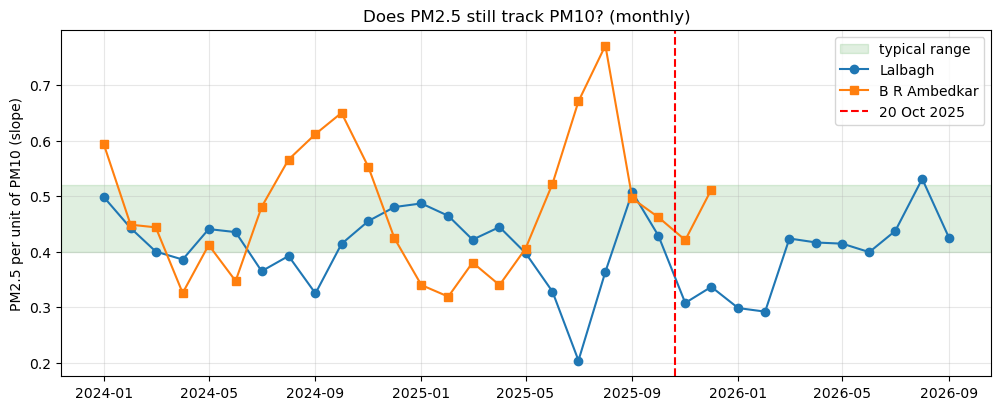

In [5]:
plt.figure(figsize=(12, 4.5))
plt.axhspan(0.40, 0.52, color="green", alpha=0.12, label="typical range")
plt.plot(lal_m.index.to_timestamp(), lal_m["slope"], marker="o", label="Lalbagh")
plt.plot(brau_m.index.to_timestamp(), brau_m["slope"], marker="s", label="B R Ambedkar")
plt.axvline(pd.Timestamp("2025-10-20"), color="red", linestyle="--", label="20 Oct 2025")
plt.ylabel("PM2.5 per unit of PM10 (slope)")
plt.title("Does PM2.5 still track PM10? (monthly)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**What you should see:** Lalbagh's slope sits in or near the green band most of the time, then falls to about **0.3** from Nov 2025 to Feb 2026 (with correlation only about 0.3 to 0.5) and climbs back to about 0.4 from March 2026. It also dips briefly in Jul 2025, but that is the monsoon, when pollution is very low and the ratio is noisy; the Nov to Feb dip is the only long one. B R Ambedkar's line swings a lot from month to month, but it does not show a long dip over those winter months.

## Step 5: When exactly did it start?
The same measure, week by week, using Lalbagh's hourly data. This pins the date.

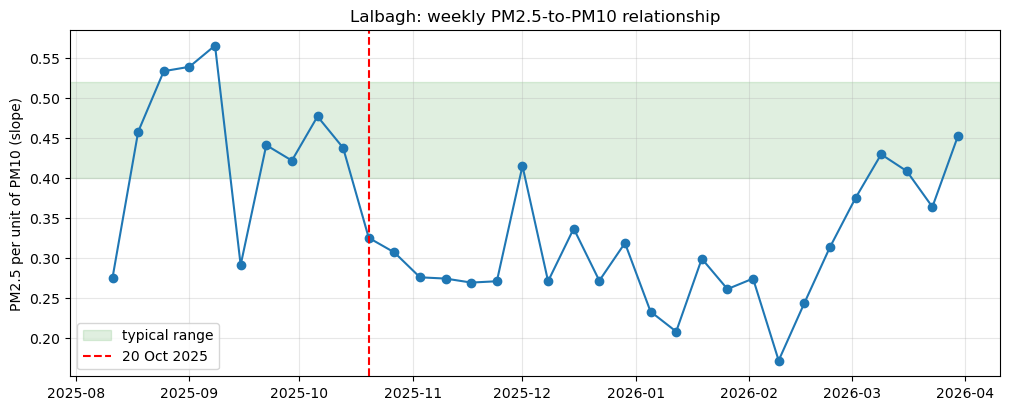

Average weekly slope before 20 Oct 2025: 0.44
Average weekly slope from 20 Oct 2025 to Feb 2026: 0.28


In [6]:
h = lal["2025-08-15":"2026-03-31"].dropna()
weekly = h.groupby(h.index.to_period("W")).apply(slope_and_corr)

plt.figure(figsize=(12, 4.5))
plt.axhspan(0.40, 0.52, color="green", alpha=0.12, label="typical range")
plt.plot(weekly.index.to_timestamp(), weekly["slope"], marker="o")
plt.axvline(pd.Timestamp("2025-10-20"), color="red", linestyle="--", label="20 Oct 2025")
plt.ylabel("PM2.5 per unit of PM10 (slope)")
plt.title("Lalbagh: weekly PM2.5-to-PM10 relationship")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print("Average weekly slope before 20 Oct 2025:", round(weekly.loc[:"2025-10-19", "slope"].mean(), 2))
print("Average weekly slope from 20 Oct 2025 to Feb 2026:", round(weekly.loc["2025-10-20":"2026-02-28", "slope"].mean(), 2))

**What you should see:** weekly slopes mostly around 0.4 to 0.5 until mid-October, then a step down to about 0.3 from the week of **20 October 2025**, staying low through winter.

## Step 6: How well do the two stations agree in general?
This is an honesty check on the **other** station too. Two stations in the same city will not match exactly (Lalbagh reads higher), but the day-to-day ups and downs should follow each other.

In [7]:
j = pd.concat([lal_daily["pm25"].rename("lalbagh"), brau["pm25"].rename("brau")], axis=1).dropna()

periods = [("Jan-Sep 2024", "2024-01-01", "2024-09-30"), ("Oct-Dec 2024", "2024-10-01", "2024-12-31"),
           ("Jan-Sep 2025", "2025-01-01", "2025-09-30"), ("Oct-Dec 2025", "2025-10-01", "2025-12-31")]
rows = []
for label, a, b in periods:
    x = j.loc[a:b]
    rows.append({"period": label, "days": len(x),
                 "Lalbagh / B R Ambedkar level": round(x["lalbagh"].mean() / x["brau"].mean(), 2),
                 "daily correlation": round(x["lalbagh"].corr(x["brau"]), 2)})
print(pd.DataFrame(rows).to_string(index=False))

      period  days  Lalbagh / B R Ambedkar level  daily correlation
Jan-Sep 2024   273                          1.41               0.76
Oct-Dec 2024    86                          1.50               0.73
Jan-Sep 2025   259                          1.47               0.18
Oct-Dec 2025    92                          1.32               0.51


**What you should see:** in 2024 the stations track each other well (correlation about 0.75) and Lalbagh reads about 1.4 to 1.5 times higher. In Jan-Sep 2025 the correlation drops to about **0.2**, which means the other station's PM2.5 was also unusual for part of 2025 (its summer values stay high where Lalbagh's drop). So **B R Ambedkar is an imperfect reference**, which is why the main evidence is Step 4: Lalbagh's PM2.5 stopping to follow Lalbagh's own PM10.

## Step 7: Conclusion and what to do

**Finding:** from about **20 October 2025** to roughly **February 2026**, Lalbagh's PM2.5 behaves abnormally: it falls far more than the other station's, and it no longer moves with its own PM10. By March 2026 it looks normal again.

**What this does not prove:** it is strong circumstantial evidence of an instrument problem, not proof. Only the station operator (UPPCB/CPCB) can confirm that.

**What to do in the project:**
1. Treat Lalbagh PM2.5 from 20 Oct 2025 onward as unreliable. Notebook 02 already removes it (Step 2b).
2. Do **not** claim that Lucknow's air improved in 2025.
3. Describe this check in your write-up: *"Detected a probable PM2.5 sensor fault by comparing against a second station and testing the PM2.5/PM10 relationship, and excluded the affected period."*

In [8]:
evidence = pd.concat({"Lalbagh": lal_m, "B R Ambedkar": brau_m}, names=["station", "month"])
evidence.round(3).to_csv("station_crosscheck_monthly.csv")
print("Saved: station_crosscheck_monthly.csv")

Saved: station_crosscheck_monthly.csv
